<a href="https://colab.research.google.com/github/ipeirotis/introduction-to-databases/blob/master/module5/orientation_model_shap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Orientation from Profile Likes: A Small ML Model with Shapley Values

**Learning objective:** use SQL to turn profile data into a feature table, train a simple classifier on it, and use Shapley values (SHAP) to see which attributes drive its predictions.

This notebook extends the [books and political views](books_and_political_views.md) example. There, we used lift to predict *Liberal* vs. *Conservative* from favorite books. Here we predict a more sensitive attribute, stated sexual orientation, from everything a profile lists: books, music, movies, TV shows, hobbies, major, political views, what the person is "looking for", and relationship status. The SQL-only version of the lift analysis is in [orientation_and_preferences.sql](orientation_and_preferences.sql).

## Why this example (and how to read it)

In 2013, Kosinski, Stillwell and Graepel showed that Facebook likes alone predict traits that people never disclosed, including sexual orientation ([PNAS, 2013](https://www.pnas.org/doi/10.1073/pnas.1218772110)). This notebook reproduces a small version of that result on the course dataset, so you can see **how little it takes**. The lesson is about privacy: a handful of harmless-looking preferences, combined, leak information that the person did not choose to share.

A few rules we follow throughout:

- **Aggregate results only.** We report accuracy and which attributes matter. We never print or export a prediction for an individual profile.
- **Minimum counts.** Every attribute in the model is listed by at least 20 people, and the lift tables require at least 15 (men) or 6 (women) people per item, so no single person's taste drives a result.
- **Correlation, not identity.** "Gay men in this 2005 sample listed *Madonna* 26x more often" is a statement about a group, in one school, at one point in time. It says nothing about any one person who likes Madonna.

## Setup

**Important:** replace `'nyu-datasets'` with your own Google Cloud project ID for billing/quota (the data itself stays in `nyu-datasets`).

In [1]:
# Authenticate with Google Cloud (only needed in Colab)
try:
    from google.colab import auth
    auth.authenticate_user()
except ImportError:
    pass  # running locally with Application Default Credentials

In [2]:
%pip install -q shap

In [3]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import shap
from google.cloud import bigquery
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

PROJECT_ID = 'nyu-datasets'  # <-- Replace with your project ID
client = bigquery.Client(project=PROJECT_ID)

def run_query(sql):
    """Run a BigQuery SQL query and return results as a pandas DataFrame."""
    return client.query(sql).to_dataframe()

pd.set_option('display.max_colwidth', 50)

## Step 1: Label the four groups (SQL)

`Profiles.Sex` combined with `Orientation.InterestedIn` gives four groups:

| Code | Sex | Interested in |
|------|-----|---------------|
| `MF` | Male | Women |
| `MM` | Male | Men |
| `FM` | Female | Men |
| `FF` | Female | Women |

Profiles that list "Men & Women", or that leave Sex blank, get `NULL` from the `CASE` and are filtered out.

A trap worth knowing: we can't write `WHERE grp IS NOT NULL` in the same `SELECT` that defines `grp`, because `WHERE` runs before the `SELECT` list is computed. We wrap the query in a derived table and filter outside it.

In [4]:
GROUPS_SQL = """
SELECT *
FROM (
  SELECT
    P.ProfileID,
    CASE
      WHEN P.Sex = 'Male'   AND O.InterestedIn = 'Women' THEN 'MF'
      WHEN P.Sex = 'Male'   AND O.InterestedIn = 'Men'   THEN 'MM'
      WHEN P.Sex = 'Female' AND O.InterestedIn = 'Men'   THEN 'FM'
      WHEN P.Sex = 'Female' AND O.InterestedIn = 'Women' THEN 'FF'
    END AS grp
  FROM `nyu-datasets.facebook.Profiles` P
    JOIN `nyu-datasets.facebook.Orientation` O ON O.ProfileID = P.ProfileID
)
WHERE grp IS NOT NULL
"""
groups = run_query(GROUPS_SQL)
groups['grp'] = groups['grp'].astype(str)
groups['grp'].value_counts()

grp
FM    7053
MF    5320
MM     476
FF      71
Name: count, dtype: int64

The groups are very unbalanced. `MM` is 476 profiles (8% of men in the sample) and `FF` is only **71** (1% of women). Keep the FF number in mind: every FF result below rests on very few people.

## Step 2: What the lift analysis shows (SQL recap)

Before any machine learning, the same lift recipe from the books/politics example already finds strong signals. We compare **within the same sex**: `MM` against `MF`, and `FF` against `FM`. Comparing `MM` against everyone would mostly rediscover gender differences (men list *Scarface* more than women do), which is not what we're after.

The query below stacks all the favorites tables with `UNION ALL`, counts each item per group with `COUNTIF`, and computes a smoothed lift.

In [5]:
LIFT_SQL = """
WITH profile_groups AS (
  {groups}
),
favorites AS (
  SELECT ProfileID, 'book' AS kind, Book AS item FROM `nyu-datasets.facebook.FavoriteBooks`
  UNION ALL
  SELECT ProfileID, 'music', Music FROM `nyu-datasets.facebook.FavoriteMusic`
  UNION ALL
  SELECT ProfileID, 'movie', Movie FROM `nyu-datasets.facebook.FavoriteMovies`
  UNION ALL
  SELECT ProfileID, 'tv', TVShow FROM `nyu-datasets.facebook.FavoriteTVShows`
  UNION ALL
  SELECT ProfileID, 'hobby', Hobby FROM `nyu-datasets.facebook.Hobbies`
),
sizes AS (
  SELECT
    COUNTIF(grp = 'MM') AS n_mm,
    COUNTIF(grp = 'MF') AS n_mf
  FROM profile_groups
)
SELECT
  F.kind,
  F.item,
  COUNTIF(G.grp = 'MM') AS cnt_mm,
  COUNTIF(G.grp = 'MF') AS cnt_mf,
  ROUND(((COUNTIF(G.grp = 'MM') + 0.5) / (ANY_VALUE(S.n_mm) + 1))
      / ((COUNTIF(G.grp = 'MF') + 0.5) / (ANY_VALUE(S.n_mf) + 1)), 1) AS lift_mm_vs_mf
FROM favorites F
  JOIN profile_groups G ON G.ProfileID = F.ProfileID
  CROSS JOIN sizes S
GROUP BY F.kind, F.item
HAVING cnt_mm >= 15
ORDER BY lift_mm_vs_mf DESC
LIMIT 10
""".format(groups=GROUPS_SQL)
run_query(LIFT_SQL)

,kind,item,cnt_mm,cnt_mf,lift_mm_vs_mf
0,movie,Brokeback Mountain,36,6,62.6
1,movie,The Hours,27,8,36.1
2,movie,Camp,22,8,29.5
3,music,Kylie Minogue,15,6,26.6
4,music,Madonna,55,23,26.3
5,music,Scissor Sisters,34,15,24.8
6,music,Tori Amos,29,13,24.4
7,movie,Drop Dead Gorgeous,18,8,24.3
8,book,Wicked,24,11,23.8
9,music,Sarah Mclachlan,15,7,23.1


Lifts of 20x to 60x are far larger than anything in the politics example (where the best books had lifts around 2 to 4). Notice also that these items are each listed by only 3% to 12% of `MM` profiles. Any single item covers a small slice of the group; the model's job is to **combine** many such weak-coverage signals.

For women, the strongest items (with only 71 FF profiles, so 6 to 8 people each) are *But I'm a Cheerleader*, *Sleater-Kinney*, and *Tegan and Sara*. See Step 6 of the `.sql` file for that query.

## Step 3: Build the feature table (SQL)

For the model, every profile becomes a row and every attribute becomes a 0/1 column ("lists *Madonna*", "politics = Very Liberal", "major = Finance", ...). SQL does the heavy lifting: it produces a **long** table with one row per (profile, feature), and keeps only features listed by at least 20 labeled profiles. The window function `COUNT(*) OVER (PARTITION BY feature)` counts each feature's support without collapsing the rows.

We also add `class_of`, extracted from the `School` field (e.g. `NYU '07` → `07`) with `REGEXP_EXTRACT`.

We deliberately leave out `Sex` and `InterestedIn` (they define the label), and identifying fields such as name, hometown, and high school.

In [6]:
FEATURES_SQL = """
WITH profile_groups AS (
  {groups}
),
long_features AS (
  SELECT ProfileID, CONCAT('book: ', Book) AS feature FROM `nyu-datasets.facebook.FavoriteBooks`
  UNION ALL
  SELECT ProfileID, CONCAT('music: ', Music) FROM `nyu-datasets.facebook.FavoriteMusic`
  UNION ALL
  SELECT ProfileID, CONCAT('movie: ', Movie) FROM `nyu-datasets.facebook.FavoriteMovies`
  UNION ALL
  SELECT ProfileID, CONCAT('tv: ', TVShow) FROM `nyu-datasets.facebook.FavoriteTVShows`
  UNION ALL
  SELECT ProfileID, CONCAT('hobby: ', Hobby) FROM `nyu-datasets.facebook.Hobbies`
  UNION ALL
  SELECT ProfileID, CONCAT('major: ', Concentration) FROM `nyu-datasets.facebook.Concentrations`
  UNION ALL
  SELECT ProfileID, CONCAT('looking for: ', LookingFor) FROM `nyu-datasets.facebook.LookingFor`
  UNION ALL
  SELECT ProfileID, CONCAT('relationship: ', Status) FROM `nyu-datasets.facebook.Relationship`
  UNION ALL
  SELECT ProfileID, CONCAT('politics: ', COALESCE(PoliticalViews, '(blank)')) FROM `nyu-datasets.facebook.Profiles`
  UNION ALL
  SELECT ProfileID, CONCAT('role: ', COALESCE(Status, '(blank)')) FROM `nyu-datasets.facebook.Profiles`
  UNION ALL
  SELECT ProfileID, CONCAT('class of: ', COALESCE(REGEXP_EXTRACT(School, r"'(\\d\\d)"), '(none)'))
  FROM `nyu-datasets.facebook.Profiles`
),
labeled AS (
  SELECT DISTINCT F.ProfileID, F.feature
  FROM long_features F
    JOIN profile_groups G ON G.ProfileID = F.ProfileID
  WHERE F.feature IS NOT NULL
)
SELECT ProfileID, feature
FROM (
  SELECT
    ProfileID,
    feature,
    COUNT(*) OVER (PARTITION BY feature) AS support
  FROM labeled
)
WHERE support >= 20
""".format(groups=GROUPS_SQL)
long = run_query(FEATURES_SQL)
print(f"{len(long):,} (profile, feature) rows, {long.feature.nunique():,} distinct features")
long.sample(8, random_state=1)[['feature']]

337,898 (profile, feature) rows, 2,909 distinct features


,feature
201008,music: Carly Simon
128222,movie: Empire Records
6546,book: Dress Your Family In Corduroy And Denim
62588,hobby: Red Wine
205340,music: Counting Crows
199368,music: Bright Eyes
174417,movie: The Notebook
5248,book: Charlie And The Chocolate Factory


Now pivot the long table into a wide 0/1 matrix. Most entries are 0 (each profile lists a few dozen of ~2,000 features), so we use a **sparse** matrix that stores only the 1s.

In [7]:
feature_names = np.array(sorted(long.feature.unique()))
col = pd.Series(np.arange(len(feature_names)), index=feature_names)
row = pd.Series(np.arange(len(groups)), index=groups.ProfileID.values)

long = long[long.ProfileID.isin(row.index)]
X_all = sp.csr_matrix(
    (np.ones(len(long), dtype=np.float32),
     (row[long.ProfileID].values, col[long.feature].values)),
    shape=(len(groups), len(feature_names)),
)
y_all = groups.grp.values
X_all.shape

(12920, 2909)

## Step 4: Model 1, men (`MM` vs `MF`)

We use **logistic regression**, the classification counterpart of linear regression. Each feature gets a weight (coefficient); the model adds up the weights of the features a profile has and turns the sum into a probability. A positive weight pushes toward `MM`, a negative one toward `MF`. This is the same idea as summing log-lifts in the politics example, except the weights are fit jointly, so overlapping signals (*Madonna* and *Kylie Minogue* tend to co-occur) are not double-counted.

Two settings matter:

- `C=0.1` adds **regularization**: it shrinks weights toward zero, so a feature seen in only 20 profiles can't get an extreme weight.
- `class_weight='balanced'` tells the model not to ignore the small `MM` class.

We evaluate with **5-fold cross-validation**: train on 80% of profiles, score the held-out 20%, rotate five times. Every profile gets a prediction from a model that never saw it.

In [8]:
def fit_and_evaluate(pos, neg, C=0.1):
    """Train pos-vs-neg logistic regression; report cross-validated metrics."""
    mask = np.isin(y_all, [pos, neg])
    X = X_all[mask]
    keep = np.asarray(X.sum(axis=0)).ravel() >= 20   # drop features too rare in this subset
    X, names = X[:, keep], feature_names[keep]
    y = (y_all[mask] == pos).astype(int)

    model = LogisticRegression(C=C, class_weight='balanced', max_iter=5000)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    p = cross_val_predict(model, X, y, cv=cv, method='predict_proba')[:, 1]

    top = np.argsort(-p)[: len(p) // 10]
    print(f"{pos} vs {neg}: {len(y):,} profiles, {y.sum()} {pos} ({y.mean():.1%}), {X.shape[1]:,} features")
    print(f"  AUC                        {roc_auc_score(y, p):.3f}   (0.5 = coin flip, 1.0 = perfect)")
    print(f"  Average precision          {average_precision_score(y, p):.3f}   (baseline = {y.mean():.3f})")
    print(f"  Precision in top 10%       {y[top].mean():.1%}   (baseline = {y.mean():.1%})")

    model.fit(X, y)  # refit on all profiles for the explanation step
    return model, X, y, names

model_m, X_m, y_m, names_m = fit_and_evaluate('MM', 'MF')

MM vs MF: 5,796 profiles, 476 MM (8.2%), 1,527 features
  AUC                        0.911   (0.5 = coin flip, 1.0 = perfect)
  Average precision          0.661   (baseline = 0.082)
  Precision in top 10%       54.2%   (baseline = 8.2%)


How to read these numbers:

- **AUC ≈ 0.91.** Pick a random `MM` profile and a random `MF` profile; 91% of the time the model gives the `MM` profile the higher score.
- **Precision in the top 10% ≈ 54%.** Among the 10% of men the model ranks as most likely `MM`, a bit over half are. That is about 6.5x the 8% base rate, and it is also wrong for nearly half of the people it flags. Strong ranking and unreliable individual labels are both true at once; this gap is why "the model says so" is never evidence about a person.

## Step 5: Which attributes drive the predictions? (Shapley values)

A **Shapley value** answers: *for this profile, how much did each feature push the prediction up or down, relative to the average profile?* The values for one profile add up exactly to (that profile's score − the average score). The idea comes from game theory: the features are "players" sharing credit for the outcome.

For a logistic regression with independent features the Shapley value has a simple form:

$$\text{SHAP}_j = w_j \times (x_j - \overline{x_j})$$

the feature's weight times how far the profile's value is from the average. The `shap` library computes this for us, and gives us standard plots.

We look at two summaries, because they answer different questions:

1. **Mean |SHAP|** (global importance): how much a feature moves predictions *across all profiles*. Common features win here, because they affect many people.
2. **Mean SHAP among profiles that list the feature** (punch per person): how much the feature moves the prediction *for someone who has it*. Rare, strong signals win here.

In [9]:
def explain(model, X, names, top=20):
    explainer = shap.LinearExplainer(model, shap.maskers.Independent(X, max_samples=X.shape[0]))
    sv = explainer(X)
    sv.feature_names = list(names)
    values = sv.values.toarray() if sp.issparse(sv.values) else np.asarray(sv.values)

    Xd = X.toarray()
    has = Xd.sum(axis=0)
    when_present = np.where(has > 0, (values * Xd).sum(axis=0) / np.maximum(has, 1), 0)
    table = pd.DataFrame({
        'profiles_with_feature': has.astype(int),
        'weight': model.coef_[0],
        'mean_abs_shap': np.abs(values).mean(axis=0),
        'shap_when_present': when_present,
    }, index=names).round(3)
    return sv, table

sv_m, table_m = explain(model_m, X_m, names_m)
table_m.sort_values('mean_abs_shap', ascending=False).head(15)

,profiles_with_feature,weight,mean_abs_shap,shap_when_present
major: Finance,797,-0.867,0.206,-0.747
looking for: A Relationship,1123,0.593,0.185,0.478
politics: Very Liberal,555,0.928,0.161,0.840
class of: 09,1195,-0.439,0.144,-0.349
class of: 08,1182,-0.431,0.140,-0.343
looking for: Friendship,2379,0.274,0.133,0.162
politics: Liberal,1625,0.317,0.128,0.228
major: Economics,602,-0.670,0.125,-0.600
movie: Pulp Fiction,592,-0.630,0.116,-0.566
politics: (blank),1270,-0.336,0.115,-0.262


Global importance is dominated by **common** attributes: political views, what the person is "looking for", major, class year, and mainstream "straight-coded" movies (*Pulp Fiction*, *Fight Club*) whose absence nudges the score up a little for many people. No single one of these is strong, but they apply to thousands of profiles.

The beeswarm plot shows the same thing per profile: each dot is one profile, its position is that feature's Shapley value for that profile, and color is the feature value (red = lists it, blue = doesn't).

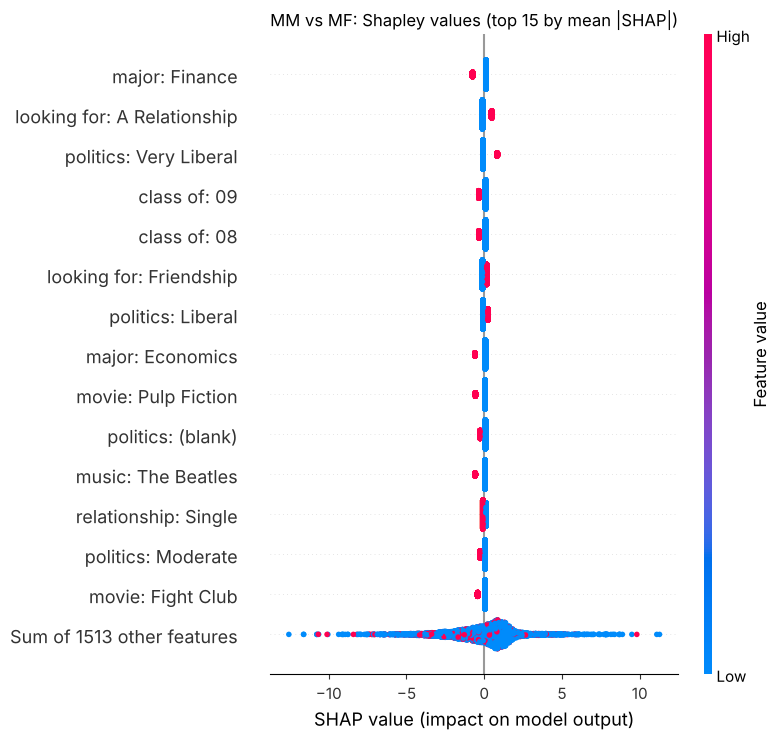

In [10]:
shap.plots.beeswarm(sv_m, max_display=15, show=False)
plt.title('MM vs MF: Shapley values (top 15 by mean |SHAP|)')
plt.tight_layout()
plt.show()

Look at the bottom row, which adds up the remaining ~1,500 features. Its spread (roughly -10 to +10) is far wider than any single row above it (each within about ±1). So the top-15 features are the most important *one at a time*, but most of a profile's score comes from the long tail: many niche items, each listed by few people, that add up.

Now sort by the push a feature gives **to the people who list it**. This recovers the lift table from Step 2: niche items with large per-person effects.

In [11]:
print('Strongest pushes toward MM, among profiles that list the feature:')
display(table_m.sort_values('shap_when_present', ascending=False).head(12))
print('Strongest pushes toward MF:')
display(table_m.sort_values('shap_when_present').head(12))

Strongest pushes toward MM, among profiles that list the feature:


,profiles_with_feature,weight,mean_abs_shap,shap_when_present
movie: Brokeback Mountain,42,1.074,0.015,1.066
music: Madonna,78,1.059,0.028,1.045
music: Scissor Sisters,49,0.895,0.015,0.888
politics: Very Liberal,555,0.928,0.161,0.840
hobby: Fashion,39,0.761,0.010,0.756
book: The Perks Of Being A Wallflower,46,0.737,0.012,0.731
movie: Moulin Rouge,107,0.733,0.027,0.719
music: Rufus Wainwright,96,0.723,0.024,0.711
movie: Y Tu Mama Tambien,80,0.720,0.020,0.711
movie: The Hours,35,0.695,0.008,0.691


Strongest pushes toward MF:


,profiles_with_feature,weight,mean_abs_shap,shap_when_present
major: Finance,797,-0.867,0.206,-0.747
movie: Old School,361,-0.717,0.084,-0.673
hobby: Baseball,192,-0.688,0.044,-0.665
hobby: Guitar,196,-0.656,0.043,-0.633
major: Computer Science,148,-0.640,0.032,-0.624
major: Accounting,177,-0.637,0.038,-0.617
hobby: Basketball,279,-0.642,0.059,-0.611
major: Film & Television,333,-0.645,0.070,-0.608
major: Economics,602,-0.670,0.125,-0.600
music: Eminem,267,-0.623,0.055,-0.595


The two rankings tell complementary stories. **Mean |SHAP|** says that profile-level attributes (politics, "looking for", major) do most of the work across the population. **SHAP when present** says that for the minority of profiles that list *Brokeback Mountain*, *Madonna* or *Scissor Sisters*, that one item moves the prediction a lot. Note that "Very Liberal" appears in both lists: it is common *and* strong. The lift table only shows the second view; Shapley values give both.

## Step 6: Model 2, women (`FF` vs `FM`)

Same pipeline, but with only 71 `FF` profiles against 7,053 `FM`.

In [12]:
model_f, X_f, y_f, names_f = fit_and_evaluate('FF', 'FM', C=0.03)

FF vs FM: 7,124 profiles, 71 FF (1.0%), 1,805 features
  AUC                        0.812   (0.5 = coin flip, 1.0 = perfect)
  Average precision          0.082   (baseline = 0.010)
  Precision in top 10%       4.8%   (baseline = 1.0%)


AUC around 0.8 looks respectable, but look at precision: in the top 10% the model is right only about 5% of the time. With a 1% base rate, even a decent ranking produces mostly false positives. This is the **base-rate problem**, and it is the main thing to take from the women's model. We used stronger regularization (`C=0.03`) because with so few positives the model overfits easily; you can try other values and compare.

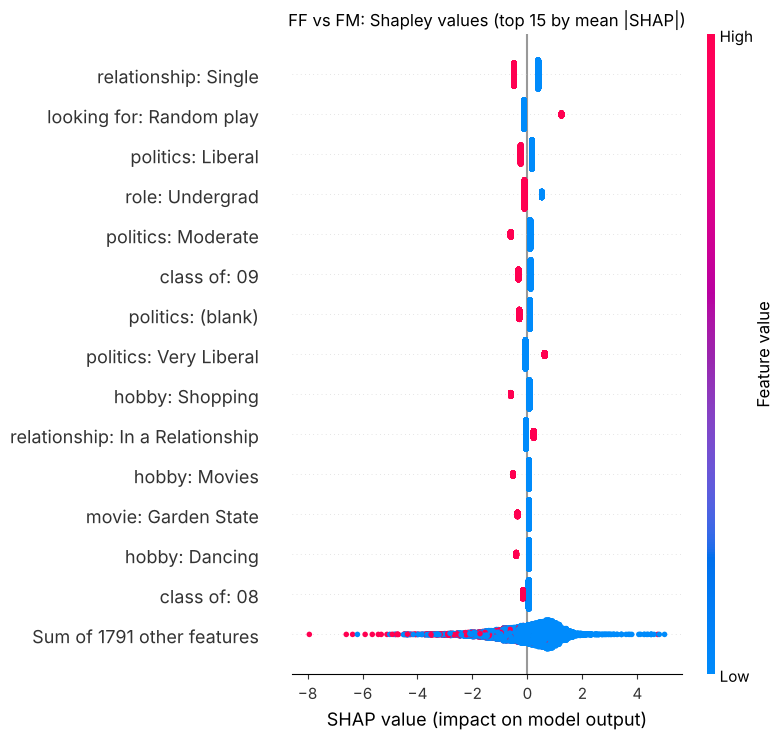

In [13]:
sv_f, table_f = explain(model_f, X_f, names_f)
shap.plots.beeswarm(sv_f, max_display=15, show=False)
plt.title('FF vs FM: Shapley values (top 15 by mean |SHAP|)')
plt.tight_layout()
plt.show()

In [14]:
print('Strongest pushes toward FF, among profiles that list the feature (at least 20 women list each):')
display(table_f.sort_values('shap_when_present', ascending=False).head(12))

Strongest pushes toward FF, among profiles that list the feature (at least 20 women list each):


,profiles_with_feature,weight,mean_abs_shap,shap_when_present
looking for: Random play,613,1.356,0.213,1.239
music: Tegan And Sara,53,0.832,0.012,0.826
major: Africana Studies,50,0.723,0.010,0.718
major: History,252,0.655,0.045,0.632
major: Dance,67,0.633,0.012,0.627
politics: Very Liberal,733,0.698,0.129,0.626
movie: I Heart Huckabees,183,0.599,0.030,0.584
music: Clap Your Hands Say Yeah,35,0.581,0.006,0.578
music: Ani Difranco,156,0.586,0.025,0.573
major: English and American Literature,345,0.582,0.054,0.553


For women, the strongest global signals are **relationship fields**, not tastes: `FF` profiles are much less likely to say "Single" and much more likely to say they are looking for "Random play". Among tastes, *Tegan and Sara* and *Ani DiFranco* carry over from the lift analysis. *But I'm a Cheerleader* does not: only 17 women list it, below our 20-profile cutoff, so it never enters the model.

Look also at *politics: Very Conservative* and *movie: Tommy Boy* in that list. Very Conservative is listed by 21 women, 3 of them `FF`; that is enough for the model to assign a sizable weight, and almost certainly noise. With 71 positive examples, treat every item in these tables as a hint, not a finding.

## Step 7: All four groups at once

Finally, the four-way version: one multinomial logistic regression that predicts `MF` / `MM` / `FM` / `FF` from the same features. **We do not give the model `Sex`**, so it has to infer gender from tastes too.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
model_4 = LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000)
p4 = cross_val_predict(model_4, X_all, y_all, cv=cv, method='predict_proba')
classes = np.array(sorted(set(y_all)))
pred4 = classes[p4.argmax(axis=1)]

cm = pd.DataFrame(confusion_matrix(y_all, pred4, labels=classes),
                  index=[f'actual {c}' for c in classes],
                  columns=[f'pred {c}' for c in classes])
display(cm)
for i, c in enumerate(classes):
    print(f"{c}: one-vs-rest AUC = {roc_auc_score(y_all == c, p4[:, i]):.3f}")

,pred FF,pred FM,pred MF,pred MM
actual FF,14,27,14,16
actual FM,154,5360,1010,529
actual MF,109,660,4235,316
actual MM,14,116,87,259


FF: one-vs-rest AUC = 0.730
FM: one-vs-rest AUC = 0.892
MF: one-vs-rest AUC = 0.909
MM: one-vs-rest AUC = 0.865


Reading the confusion matrix by rows: the model guesses gender from tastes correctly for most profiles, but not all (roughly 1 in 7 `FM` profiles is predicted `MF`, and 1 in 8 `MF` is predicted `FM`). Within each sex, `class_weight='balanced'` makes the model flag far more profiles as `MM` or `FF` than actually are (about 1,100 predicted `MM` for 476 actual, and about 290 predicted `FF` for 71 actual). Most of those flags are false positives, as in Steps 4 and 6. Only 14 of the 71 `FF` profiles are predicted `FF`.

Which features does each class lean on? For a multinomial model, `shap` returns one set of Shapley values per class.

In [16]:
model_4.fit(X_all, y_all)
explainer4 = shap.LinearExplainer(model_4, shap.maskers.Independent(X_all, max_samples=X_all.shape[0]))
sv4 = explainer4(X_all)
vals4 = sv4.values.toarray() if sp.issparse(sv4.values) else np.asarray(sv4.values)  # (profiles, features, classes)

top_features = pd.DataFrame({
    c: pd.Series(np.abs(vals4[:, :, i]).mean(axis=0), index=feature_names).nlargest(8).index
    for i, c in enumerate(model_4.classes_)
})
top_features.index = range(1, 9)
top_features

,FF,FM,MF,MM
1,relationship: Single,relationship: Single,relationship: Single,looking for: A Relationship
2,looking for: Random play,looking for: Random play,looking for: Friendship,class of: 08
3,looking for: A Relationship,role: Undergrad,relationship: Married,politics: (blank)
4,relationship: In a Relationship,politics: (blank),politics: Very Liberal,class of: 09
5,hobby: Movies,politics: Liberal,major: Finance,relationship: In a Relationship
6,major: Psychology,hobby: Shopping,hobby: Shopping,relationship: Single
7,role: Undergrad,class of: 09,politics: Liberal,movie: Old School
8,politics: Moderate,hobby: Dancing,looking for: A Relationship,movie: Pulp Fiction


By mean |SHAP|, all four classes lean mostly on **profile fields** (relationship status, "looking for", political views, class year), with a few common tastes mixed in (*Shopping* and *Dancing* for `FM`; *Old School* and *Pulp Fiction* pushing away from `MM`). As in Step 5, the niche tastes with large per-person effects sit lower in this ranking because few people list them. Try computing the "SHAP when present" table for each class as an exercise.

## Takeaways

**SQL concepts used**
- `CASE` to build labels from two columns; a derived table to filter on a computed column.
- `UNION ALL` to stack similar tables into one long table.
- `COUNTIF` to count several groups in one `GROUP BY` instead of one temp table per group.
- A window function (`COUNT(*) OVER (PARTITION BY ...)`) to filter rows by group size without collapsing them.
- `REGEXP_EXTRACT` to pull the class year out of a text field.

**Analytics concepts**
- Compare within the same sex, or the result mostly measures gender.
- Logistic regression generalizes the "sum of log-lifts" scorer from the politics example.
- Shapley values split each prediction into per-feature contributions. Mean |SHAP| ranks features by population-wide impact; SHAP-when-present ranks them by per-person impact.
- A high AUC can coexist with mostly-wrong individual flags when the group is small (the base-rate problem).

**Caveats**
- The data is self-reported, from one university around 2005. Who chose to fill in "Interested in" is itself selective, and tastes have changed.
- "Married" and "In an Open Relationship" were often joke entries among friends on early Facebook, so the relationship fields are noisy.
- These are population-level correlations. They describe groups in this sample, not individuals.

**Privacy**

Nobody in this dataset was asked whether their favorite movies could be used to guess their orientation. A few dozen likes were enough to rank people far better than chance. Platforms, advertisers, and data brokers can do the same with much more data. When you build models on behavioral data in your own work, ask which sensitive attributes they could reveal, even when those attributes are not in the data.